# Pleiades Building (PLEIAData) — Exploratory Data Analysis

**Digital Twins (530.091), WS 2026/27 · Data foundation**

**Dataset:** *PLEIAData: consumption, HVAC, temperature, weather and motion sensor data for smart buildings applications* — Martínez Ibarra, González-Vidal & Skarmeta, *Scientific Data* 10, 118 (2023). Data from the **Pleiades building, University of Murcia (Spain)**, a pilot building of the EU PHOENIX project. Files: the `Data_Nature` folder next to this notebook.

**Goal of this notebook:** understand the system behind the data, check its quality, and answer the project questions: how the inputs affect the output, what we can and cannot control, what is missing, how fast the system changes and whether the history is long enough. Each question is answered in an **Answer** box right after the analysis that supports it. A summary and the modelling decisions are at the end.

| # | Question | Section |
|---|---|---|
| Q1 | Is this a physical system? Which physical components are we looking at? | 2 |
| Q2 | Is the data clean and trustworthy? What needs cleaning? | 3 |
| Q3 | How does the output behave? Day vs. night, weekday vs. weekend, seasons? | 4–5 |
| Q4 | How fast does the system change? | 6 |
| Q5 | How do the inputs affect the output? | 7 |
| Q6 | How many variables do we actually need? | 8 |
| Q7 | Cause or effect? | 9 |
| Q8 | What can we control and what not? | 10 |
| Q9 | What is missing (hidden states), and why would it help? | 11 |
| Q10 | Is the history long enough? How much data do we need? | 12 |

## 1. Setup and loading

Only standard libraries are used (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`). The notebook reads the **raw** electricity, weather and motion files, and the authors' **processed** hourly HVAC and indoor-temperature aggregates. The very large raw files (`data-sensor.csv`, `data-hvac.csv`, `data-CO2.csv`, 0.2–0.6 GB each) are not loaded here.

**How electricity is computed.** Each block has one *cumulative* meter (a running kWh total, read about every 10 minutes). The energy used in an hour is the difference of the meter between the start and the end of that hour. When the meter stops reporting for more than an hour, those hours are set to **missing** instead of guessing, because the meter then registers the whole gap's energy in one lump.

In [4]:
! pip install numpy pandas matplotlib seaborn scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 17.6 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 14.3 MB/s  0:00:00m0:00:0100:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 28.9 MB/s  0:00:00
Using cach

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch, FancyBboxPatch
import seaborn as sns
import textwrap, warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
warnings.filterwarnings("ignore")

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", red="#e34948", violet="#6250d6",
         ink="#0b0b0b", ink2="#52514e", muted="#898781", grid="#e1e0d9", surf="#fcfcfb")
BLOCK_COL = {"A": C["blue"], "B": C["orange"], "C": C["aqua"]}
plt.rcParams.update({
    "figure.facecolor": C["surf"], "axes.facecolor": C["surf"], "savefig.facecolor": C["surf"],
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 110, "font.size": 10,
})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

RAW, PROC = "data/Data_Nature/processed_data/"
TZ = "Europe/Madrid"          # local time of the building (for daily routines)
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

ValueError: too many values to unpack (expected 2)

In [2]:
# --- Electricity: one cumulative meter (kWh) per block, read about every 10 minutes
cons_raw = pd.read_csv(RAW + "data-cons.csv", sep=";")
cons_raw["Date"] = pd.to_datetime(cons_raw["Date"], utc=True, format="mixed")
cons_raw["block"] = cons_raw["IDdevice"].map({335546928: "A", 335546926: "B", 335546927: "C"})

grid = pd.date_range("2021-01-01", "2022-01-01", freq="h", tz="UTC")
hourly, gaps = {}, []
for b, g in cons_raw.groupby("block"):
    s = g.set_index("Date")["V22"].sort_index()
    s = s[~s.index.duplicated()]
    step = s.index.to_series().diff()
    # interpolate the cumulative meter onto the hourly grid ...
    u = s.reindex(s.index.union(grid)).interpolate("time", limit_area="inside")
    # ... but never across a reporting gap longer than 1 h (those hours become missing)
    for end, d in step[step > pd.Timedelta("1h")].items():
        u[(u.index > end - d) & (u.index < end)] = np.nan
        if b == "A": gaps.append((end - d, end, d))
    hourly[b] = u.reindex(grid).diff().shift(-1)      # kWh used in the hour starting at t
cons = pd.DataFrame(hourly).iloc[:-1]
cons["total"] = cons[["A", "B", "C"]].sum(axis=1, min_count=3)

print("Raw meter readings per block:", cons_raw.groupby("block").size().to_dict())
print("Reporting gaps longer than 1 h (identical for all three meters):")
for start, end, d in gaps:
    print(f"   {start:%d %b %H:%M} -> {end:%d %b %H:%M} UTC  ({d.total_seconds()/3600:.0f} h)")
print(f"Hourly grid: {len(cons):,} hours, missing: {cons.total.isna().sum()} h ({cons.total.isna().mean():.1%})")
annual = cons[["A","B","C","total"]].sum() / 1000
print("Energy in 2021 (MWh, without the gaps):", annual.round(1).to_dict())
cons.describe().round(2)

Raw meter readings per block: {'A': 51611, 'B': 51611, 'C': 51611}
Reporting gaps longer than 1 h (identical for all three meters):
   12 Aug 02:16 -> 15 Aug 23:05 UTC  (93 h)
   10 Dec 15:16 -> 13 Dec 07:33 UTC  (64 h)
Hourly grid: 8,760 hours, missing: 161 h (1.8%)
Energy in 2021 (MWh, without the gaps): {'A': 41.0, 'B': 22.9, 'C': 41.9, 'total': 105.7}


,A,B,C,total
count,8599.00,8599.00,8599.00,8599.00
mean,4.76,2.67,4.87,12.30
std,3.01,1.88,6.79,9.54
min,0.02,0.07,0.00,0.09
25%,2.41,0.81,0.67,6.54
50%,4.13,2.70,2.52,8.91
75%,6.52,3.59,5.21,13.69
max,27.64,13.85,48.10,79.43


In [3]:
# --- Weather: IMIDA station MU62 (Murcia), every 10 min, timestamps in UTC
w = pd.read_csv(RAW + "MU62_dm.txt", sep=";", skipinitialspace=True)
w.columns = [c.strip() for c in w.columns]
w["Date"] = pd.to_datetime(w["fecha"] + " " + w["hora"], format="%d/%m/%y %H:%M:%S").dt.tz_localize("UTC")
w = w.set_index("Date").sort_index()
weather = w[["tmed", "hrmed", "radmed", "vvmed", "prec", "dewpt"]].resample("h").mean().loc["2021"]

# --- HVAC (authors' hourly aggregate per block): V4 = number of units ON, V12 = mean setpoint,
#     V5_* = dominant mode (0 none, 1 heating, 2 cooling)
hvac = {}
for b in "ABC":
    x = pd.read_csv(PROC + f"hvac-agg{b}-60T.csv", sep=";", parse_dates=["Date"]).set_index("Date")
    hvac[b] = x
units_on = pd.DataFrame({b: hvac[b]["V4"] for b in "ABC"}); units_on["total"] = units_on.sum(axis=1)
setpoint = pd.DataFrame({b: hvac[b]["V12"] for b in "ABC"})
mode = pd.DataFrame({b: hvac[b][["V5_0", "V5_1", "V5_2"]].values.argmax(axis=1) for b in "ABC"}, index=hvac["A"].index)

# --- Indoor temperature (authors' hourly mean over each block's room sensors, outliers removed)
tin = pd.DataFrame({b: pd.read_csv(PROC + f"temp-sensor{b}-60T.csv", sep=";", parse_dates=["Date"]).set_index("Date")["V2"] for b in "ABC"})

# --- Motion sensors (12 rooms in blocks A and B): 1 = movement detected
pres = pd.read_csv(RAW + "data-presence.csv")
pres["Date"] = pd.to_datetime(pres["Date"], utc=True, format="mixed")
rel_p = pd.read_csv(RAW + "relations-presence.csv", sep=";")
pres = pres[pres.IDdevice.isin(rel_p.ID)].merge(rel_p, left_on="IDdevice", right_on="ID")
ev = pres[pres.V2 == 1].assign(hour=lambda d: d.Date.dt.floor("h"))
room_hours = ev.groupby(["hour", "IDdevice"]).size().unstack().reindex(grid[:-1]).notna()
occ_share = room_hours.mean(axis=1).rename("occ")      # share of the 12 rooms with movement in that hour

rel_h = pd.read_csv(RAW + "relations-hvac.csv", sep=";"); rel_s = pd.read_csv(RAW + "relations-sensor.csv", sep=";")
for name, s in [("weather", weather.tmed), ("HVAC", units_on.total), ("indoor temp", tin.A), ("motion", ev.Date)]:
    idx = s.index if name != "motion" else pd.DatetimeIndex(s)
    print(f"{name:12s}: {idx.min():%d %b %Y} -> {idx.max():%d %b %Y}")
print(f"HVAC units per block: {rel_h.groupby('block').size().to_dict()}   room temperature sensors per block: {rel_s.groupby('block').size().to_dict()}")
print(f"Motion-sensor rooms: {len(rel_p)} (block A: {(rel_p.block=='A').sum()}, block B: {(rel_p.block=='B').sum()})")

# --- One hourly table for the whole analysis
df = pd.concat([cons, weather, units_on.total.rename("on"), setpoint.add_prefix("sp_"),
                tin.mean(axis=1).rename("tin"), occ_share], axis=1, sort=True).loc["2021"]
loc = df.tz_convert(TZ)
loc["hour"], loc["dow"], loc["month"] = loc.index.hour, loc.index.dayofweek, loc.index.month
season_of = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
loc["season"] = loc.month.map(season_of)
df.head(3)

weather     : 01 Jan 2021 -> 31 Dec 2021
HVAC        : 01 Jan 2021 -> 18 Dec 2021
indoor temp : 01 Jan 2021 -> 18 Dec 2021
motion      : 04 Jan 2021 -> 31 Dec 2021
HVAC units per block: {'A': 49, 'B': 23, 'C': 15}   room temperature sensors per block: {'A': 49, 'B': 35, 'C': 6}
Motion-sensor rooms: 12 (block A: 4, block B: 8)


,A,B,C,total,tmed,hrmed,radmed,vvmed,prec,dewpt,on,sp_A,sp_B,sp_C,tin,occ
2021-01-01 00:00:00+00:00,1.344675,4.156200,0.685263,6.186138,3.340000,64.400000,0.0,0.280000,0.0,-2.72,4.0,14.1,23.91,25.14,NaN,0.0
2021-01-01 01:00:00+00:00,1.311073,4.140135,0.677097,6.128305,2.783333,67.283333,0.0,0.366667,0.0,-2.70,4.0,14.1,23.91,25.14,21.912995,0.0
2021-01-01 02:00:00+00:00,1.296574,4.082916,0.676272,6.055762,3.166667,67.000000,0.0,0.266667,0.0,-2.40,4.0,14.1,23.91,25.14,21.868722,0.0


## 2. The physical system behind the data (Q1)

The Pleiades building is a university building with offices and teaching/research rooms, split into **three blocks (A, B, C)**. It is heated and cooled by **87 individual HVAC units** (split units on walls or ceilings, each with its own on/off switch, setpoint and mode). Roughly **90 room temperature sensors**, a **local weather station** (IMIDA, station MU62) and **motion + CO₂ sensors in 12 rooms** complete the picture.

| Signal | Unit | Role | Resolution |
|---|---|---|---|
| Electricity per block (A, B, C) | kWh, cumulative | **y output (target)** | ~10 min |
| HVAC on/off, setpoint, mode (87 units) | –, °C, category | **u controllable inputs** | event log (aggregated hourly) |
| Outdoor temperature, humidity, solar radiation, wind, rain, dew point | °C, %, W/m², m/s, mm | **d disturbances** | 10 min |
| Room temperature (~90 sensors) | °C | **x states (measured)** | event log (aggregated hourly) |
| Motion (12 rooms), CO₂ (12 rooms) | 0/1, ppm | partial view of **occupancy (d)** | event log |

### The System Canvas

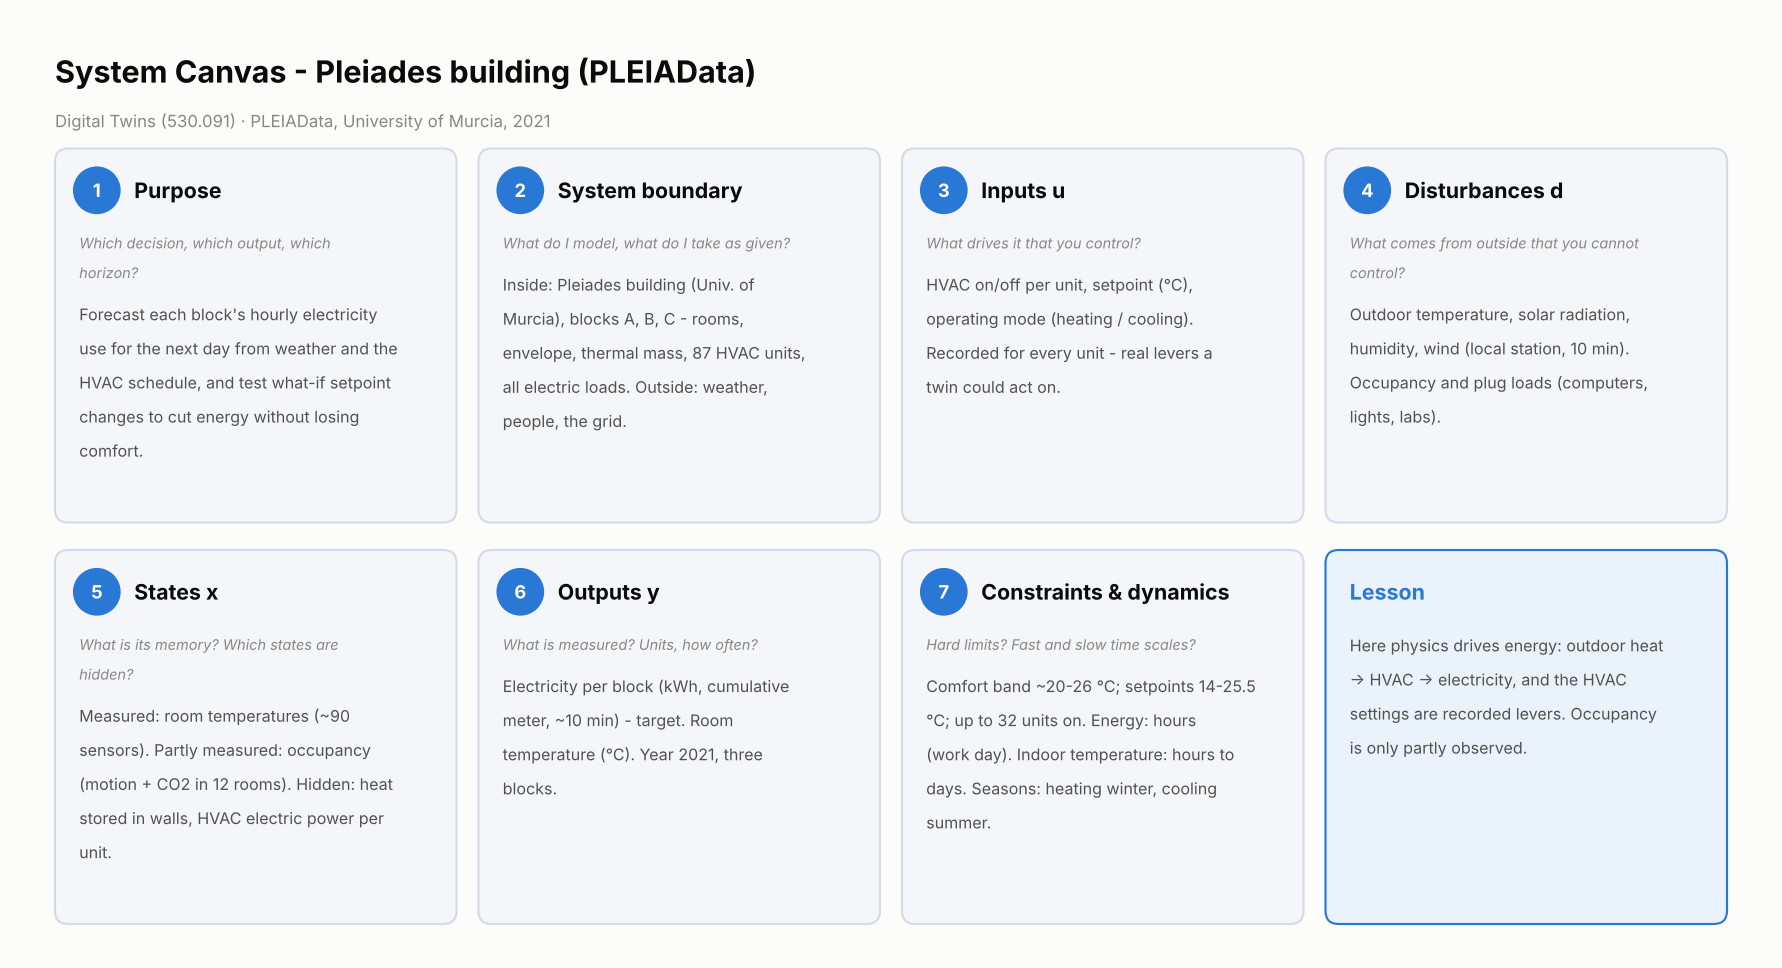

In [4]:
def draw_canvas(boxes, title, subtitle, path=None):
    INK, INK2, MUTED, BOX, EDGE, ACC = "#0b0b0b", "#52514e", "#898781", "#f4f6fa", "#d5dbe6", "#2a78d6"
    fig = plt.figure(figsize=(16, 8.6), dpi=110); fig.patch.set_facecolor("white")
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 16); ax.set_ylim(0, 8.6); ax.axis("off")
    ax.text(0.4, 8.05, title, fontsize=20, fontweight="bold", color=INK, va="center")
    ax.text(0.4, 7.6, subtitle, fontsize=11, color=MUTED, va="center")
    w, gap = 3.65, 0.2
    for i, (num, head, sub, body) in enumerate(boxes):
        r, col = divmod(i, 4); x = 0.4 + col * (w + gap); y = 3.95 - r * 3.65; h = 3.4
        lesson = num == ""
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.12",
                     fc="#eaf2fc" if lesson else BOX, ec=ACC if lesson else EDGE, lw=1.4))
        tx = x + 0.22
        if num:
            ax.add_patch(plt.Circle((x + 0.38, y + h - 0.38), 0.21, color=ACC))
            ax.text(x + 0.38, y + h - 0.38, num, color="white", fontsize=12, fontweight="bold", ha="center", va="center")
            tx = x + 0.72
        ax.text(tx, y + h - 0.38, head, fontsize=14, fontweight="bold", color=ACC if lesson else INK, va="center")
        yy = y + h - 0.78
        for line in textwrap.wrap(sub, 42):
            ax.text(x + 0.22, yy, line, fontsize=9.5, color=MUTED, style="italic", va="top"); yy -= 0.27
        yy -= 0.1 if sub else 0
        for line in textwrap.wrap(body, 41):
            ax.text(x + 0.22, yy, line, fontsize=10.5, color=INK2, va="top"); yy -= 0.31
    if path: fig.savefig(path, facecolor="white")
    return fig

CANVAS = [
    ("1", "Purpose", "Which decision, which output, which horizon?",
     "Forecast each block's hourly electricity use for the next day from weather and the HVAC schedule, "
     "and test what-if setpoint changes to cut energy without losing comfort."),
    ("2", "System boundary", "What do I model, what do I take as given?",
     "Inside: Pleiades building (Univ. of Murcia), blocks A, B, C - rooms, envelope, thermal mass, "
     "87 HVAC units, all electric loads. Outside: weather, people, the grid."),
    ("3", "Inputs u", "What drives it that you control?",
     "HVAC on/off per unit, setpoint (°C), operating mode (heating / cooling). "
     "Recorded for every unit - real levers a twin could act on."),
    ("4", "Disturbances d", "What comes from outside that you cannot control?",
     "Outdoor temperature, solar radiation, humidity, wind (local station, 10 min). "
     "Occupancy and plug loads (computers, lights, labs)."),
    ("5", "States x", "What is its memory? Which states are hidden?",
     "Measured: room temperatures (~90 sensors). Partly measured: occupancy (motion + CO2 in 12 rooms). "
     "Hidden: heat stored in walls, HVAC electric power per unit."),
    ("6", "Outputs y", "What is measured? Units, how often?",
     "Electricity per block (kWh, cumulative meter, ~10 min) - target. Room temperature (°C). "
     "Year 2021, three blocks."),
    ("7", "Constraints & dynamics", "Hard limits? Fast and slow time scales?",
     "Comfort band ~20-26 °C; setpoints 14-25.5 °C; up to 32 units on. Energy: hours (work day). "
     "Indoor temperature: hours to days. Seasons: heating winter, cooling summer."),
    ("", "Lesson", "",
     "Here physics drives energy: outdoor heat -> HVAC -> electricity, and the HVAC settings are "
     "recorded levers. Occupancy is only partly observed."),
]
fig = draw_canvas(CANVAS, "System Canvas - Pleiades building (PLEIAData)",
                  "Digital Twins (530.091) · PLEIAData, University of Murcia, 2021", "system_canvas_pleiadata.png")
plt.show()

> **Answer Q1: Is this a physical system, and which components?**
>
> **Yes, clearly.** A real building with real meters, time-indexed, documented, published in a peer-reviewed data journal, and covering a full year. The physical components are:
> * the **building envelope and rooms** of three blocks, with their thermal mass,
> * the **HVAC system**: 87 heat-pump split units that heat in winter and cool in summer,
> * the **electrical system**: three block meters measuring everything (HVAC, lights, computers, labs),
> * the **outdoor environment**: weather measured by a local station.
>
> Unlike a household dataset, there is a **physical chain** from input to output: outdoor heat → room temperature → HVAC work → electricity. Sections 7 and 9 measure how strong it is.

## 3. Data quality checks (Q2)

In [5]:
# 1) Meter readings: are there jumps after the outages? (cumulative meter = energy is not lost, it is lumped)
jump = {}
for b, g in cons_raw.groupby("block"):
    g = g.sort_values("Date"); d = g["V22"].diff(); dt = g["Date"].diff().dt.total_seconds() / 3600
    jump[b] = (d[dt > 1].round(1).tolist())
print("kWh registered in the first reading after each gap (lumped energy):", jump)
print("Meter ever decreasing:", any((g.sort_values('Date')['V22'].diff() < 0).any() for _, g in cons_raw.groupby('block')))

# 2) HVAC log: long stretches where the number of units ON never changes are suspicious
x = units_on["total"]; run = (x != x.shift()).cumsum(); L = x.groupby(run).transform("size")
print(f"HVAC data ends: {units_on.index.max():%d %b %Y}")
print(f"Share of hours inside a constant run longer than 48 h: {(L > 48).mean():.0%}  (longest: {L.max()} h = {L.max()/24:.0f} days)")

# 3) Weather station
st = w.index.to_series().diff().value_counts()
print("Weather sampling steps:", {str(k): int(v) for k, v in st.head(3).items()}, " missing hours in 2021:", int(weather.tmed.isna().sum()))

# 4) Motion sensors: how much data per room?
cnt = ev.groupby("room").size().sort_values()
print("Motion events per room in 2021 (min / median / max):", int(cnt.min()), int(cnt.median()), int(cnt.max()))

# 5) Ranges of the cleaned hourly table
df[["A","B","C","total","tmed","radmed","hrmed","on","tin","sp_A","sp_B","sp_C"]].describe().T.round(1)

kWh registered in the first reading after each gap (lumped energy): {'A': [712.5, 135.4], 'B': [326.5, 246.0], 'C': [576.6, 43.2]}
Meter ever decreasing: False
HVAC data ends: 18 Dec 2021
Share of hours inside a constant run longer than 48 h: 36%  (longest: 417 h = 17 days)
Weather sampling steps: {'0 days 00:10:00': 54938, '0 days 00:08:00': 386, '0 days 00:12:00': 386}  missing hours in 2021: 463
Motion events per room in 2021 (min / median / max): 162 2345 6991


,count,mean,std,min,25%,50%,75%,max
A,8599.0,4.8,3.0,0.0,2.4,4.1,6.5,27.6
B,8599.0,2.7,1.9,0.1,0.8,2.7,3.6,13.8
C,8599.0,4.9,6.8,0.0,0.7,2.5,5.2,48.1
total,8599.0,12.3,9.5,0.1,6.5,8.9,13.7,79.4
tmed,8297.0,19.1,7.6,-1.8,13.3,18.7,24.5,45.8
radmed,8297.0,201.7,284.8,0.0,0.0,10.7,369.1,1078.7
hrmed,8297.0,57.0,19.4,5.2,41.2,58.1,73.1,93.4
on,8425.0,10.7,4.7,0.0,7.0,11.0,13.0,32.0
tin,8424.0,26.7,3.1,19.5,24.1,26.6,29.7,32.2
sp_A,8425.0,18.5,1.5,14.1,17.2,19.1,19.7,21.2


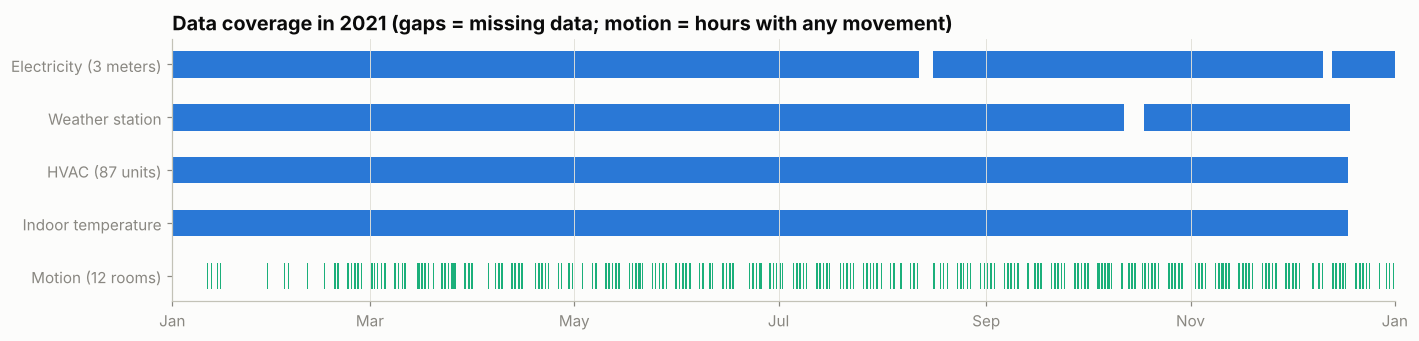

In [6]:
fig, ax = plt.subplots(figsize=(13, 3.2))
series = [("Electricity (3 meters)", cons.total), ("Weather station", weather.tmed), ("HVAC (87 units)", units_on.total),
          ("Indoor temperature", tin.A), ("Motion (12 rooms)", occ_share.where(occ_share > 0))]
for i, (name, s) in enumerate(series[::-1]):
    s = s.loc["2021"]; ok = s.notna()
    # draw available hours as bars, missing hours as gaps
    blocks = (ok != ok.shift()).cumsum()
    for _, seg in s[ok].groupby(blocks[ok]):
        ax.barh(i, (seg.index[-1] - seg.index[0]).total_seconds() / 86400 + 1/24, left=mdates.date2num(seg.index[0]),
                height=0.5, color=C["blue"] if name != "Motion (12 rooms)" else C["aqua"])
ax.set_yticks(range(len(series))); ax.set_yticklabels([n for n, _ in series[::-1]])
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(mdates.date2num(pd.Timestamp("2021-01-01")), mdates.date2num(pd.Timestamp("2022-01-01")))
ax.set_title("Data coverage in 2021 (gaps = missing data; motion = hours with any movement)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**What the checks show**

* **Two meter outages**, the same for all three meters (so it is a logging failure, not a meter fault): **12–15 Aug (93 h)** and **10–13 Dec (64 h)**. After each outage the meter reports the energy of the whole gap in one reading (up to 713 kWh at once). A naive difference would create huge fake peaks; we mark those hours as missing instead. In total **161 h (1.8 %)** of the year are missing. Readings never decrease, so the meters themselves are consistent.
* **Weather station:** clean 10-minute data with two gaps: **12–18 Oct (~6 days)** and **from 18 Dec to the end of the year**.
* **HVAC log ends on 18 Dec**, and **36 % of the hours** sit in stretches of more than 48 h where the number of units ON never changes (longest: 17 days). Some of this is real (nights, weekends), but 17 days without a single change points to missing log entries that were forward-filled. **The HVAC series needs cleaning** before it is trusted as a model input (Section 11 shows the consequence).
* **Motion sensors** report very unevenly: from 162 to 6,991 events per room over the whole year. A motion sensor only fires when someone moves, so it is an *indicator* of occupancy, not a head count.
* **Indoor temperature (block average)** is plausible (19–34 °C) but is a mean over many rooms, including rooms without air conditioning, which is why summer averages reach ~31 °C. For comfort questions the room-level file (`data-room10T-all.csv`) is needed.

> **Answer Q2: Is the data clean, and what needs cleaning?**
>
> Usable, but **not ready-made**, which gives us work for the "justified cleaning" grading criterion:
> 1. **Electricity:** set the two outage periods to missing; never difference across a gap (otherwise fake peaks of hundreds of kWh).
> 2. **Weather:** two gaps (Oct, late Dec): short ones can be interpolated, the late-December gap means the study period effectively ends on **17 Dec** for anything that needs weather or HVAC.
> 3. **HVAC:** check the long constant stretches in the raw event log and rebuild the "units ON" series from the raw data.
> 4. **Motion:** treat as a presence indicator per room, aggregated per hour.

## 4. How the output behaves (Q3)

Monthly electricity (MWh):
       Jan  Feb  Mar  Apr  May   Jun   Jul   Aug   Sep  Oct  Nov  Dec
A      2.3  2.1  1.8  1.9  3.1   4.3   7.1   4.6   5.7  4.4  2.2  1.5
B      3.3  2.2  3.2  1.2  0.5   0.6   2.5   2.3   1.8  0.8  2.1  2.4
C      3.2  0.9  1.6  1.9  4.2   5.4   8.0   4.6   6.8  2.1  1.0  1.9
total  8.8  5.2  6.6  5.0  7.9  10.3  17.6  11.5  14.4  7.3  5.3  5.8

Hourly total: median 8.9 kWh, 95th pct 33.3, max 79.4; skewness 2.47
Daily total: min 89, median 246, max 931 kWh


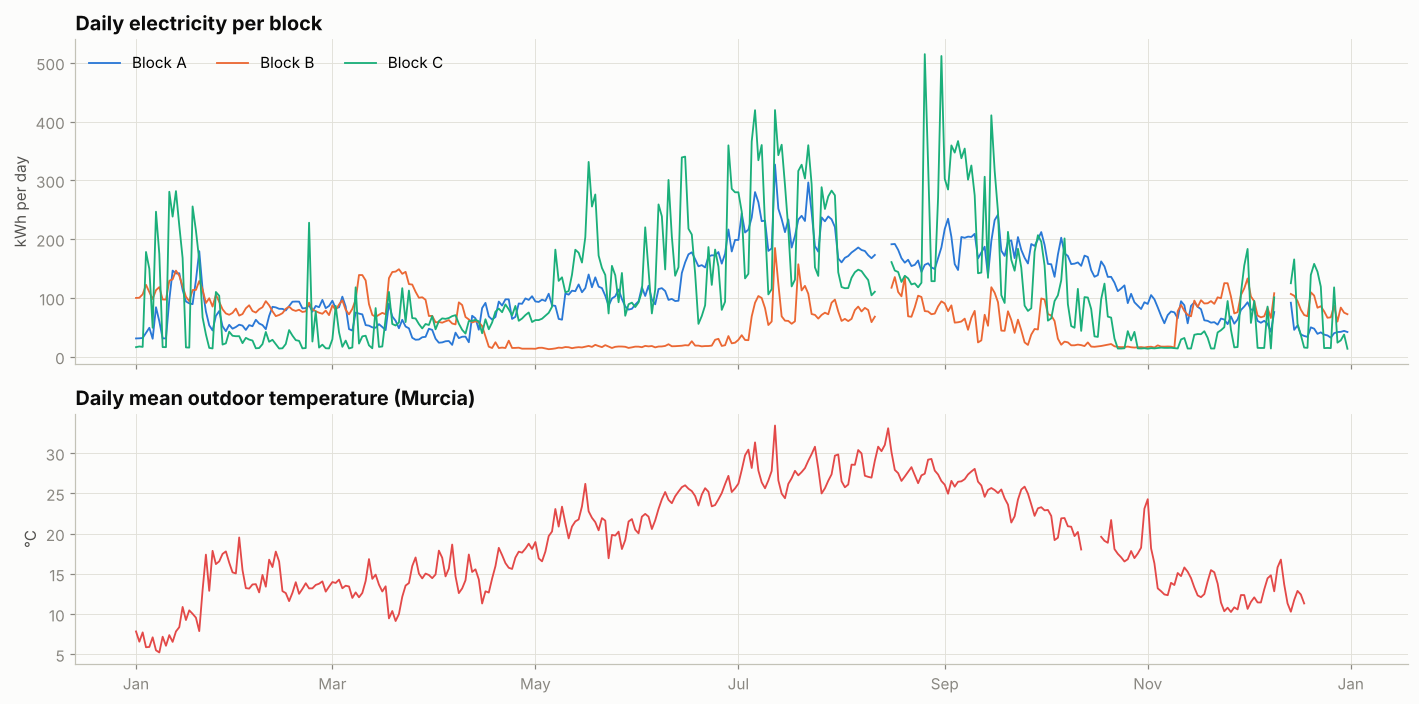

In [7]:
daily = cons.resample("D").sum(min_count=20)
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
for b in "ABC":
    ax[0].plot(daily.index, daily[b], color=BLOCK_COL[b], lw=1.2, label=f"Block {b}")
ax[0].set_title("Daily electricity per block"); ax[0].set_ylabel("kWh per day"); ax[0].legend(loc="upper left", ncol=3)
ax[1].plot(weather.tmed.resample("D").mean(), color=C["red"], lw=1.2)
ax[1].set_title("Daily mean outdoor temperature (Murcia)"); ax[1].set_ylabel("°C")
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()

monthly = cons[["A","B","C","total"]].resample("MS").sum()
monthly.index = MONTHS
print("Monthly electricity (MWh):"); print((monthly / 1000).round(1).T.to_string())
print(f"\nHourly total: median {cons.total.median():.1f} kWh, 95th pct {cons.total.quantile(.95):.1f}, max {cons.total.max():.1f}; skewness {cons.total.skew():.2f}")
print(f"Daily total: min {daily.total.min():.0f}, median {daily.total.median():.0f}, max {daily.total.max():.0f} kWh")

**What we see**

* The building used **≈ 106 MWh in 2021** (A 41, B 23, C 42 MWh).
* The annual shape is driven by **cooling**: consumption is highest in **July (17.6 MWh)** and September, lowest in spring (April 5.0 MWh). January shows a smaller **heating** peak.
* **August is a dip** (11.5 MWh) although it is the hottest month (mean 28 °C). The university is largely closed in August, so the **academic calendar** clearly shapes energy use.
* **The blocks behave differently.** A and C peak in summer (cooling); **B peaks in winter** and is almost idle from April to June. B probably has different use or equipment, so the daily energy of B is uncorrelated with A (r ≈ −0.07). This supports **one model per block**.
* Hourly values range from ~0 to 79 kWh, with a right-skewed distribution (median 8.9 kWh/h).

## 5. Day vs. night, weekday vs. weekend, seasons (Q3)

Night (00–06): 8.4 kWh/h | weekday 08–20: 17.9 kWh/h (2.1× night) | weekend 08–20: 10.4 kWh/h
  Winter  weekday peak 20.1 kWh/h at 10:00, night 6.9
  Spring  weekday peak 13.4 kWh/h at 11:00, night 7.2
  Summer  weekday peak 37.0 kWh/h at 13:00, night 11.2
  Autumn  weekday peak 23.0 kWh/h at 13:00, night 8.6


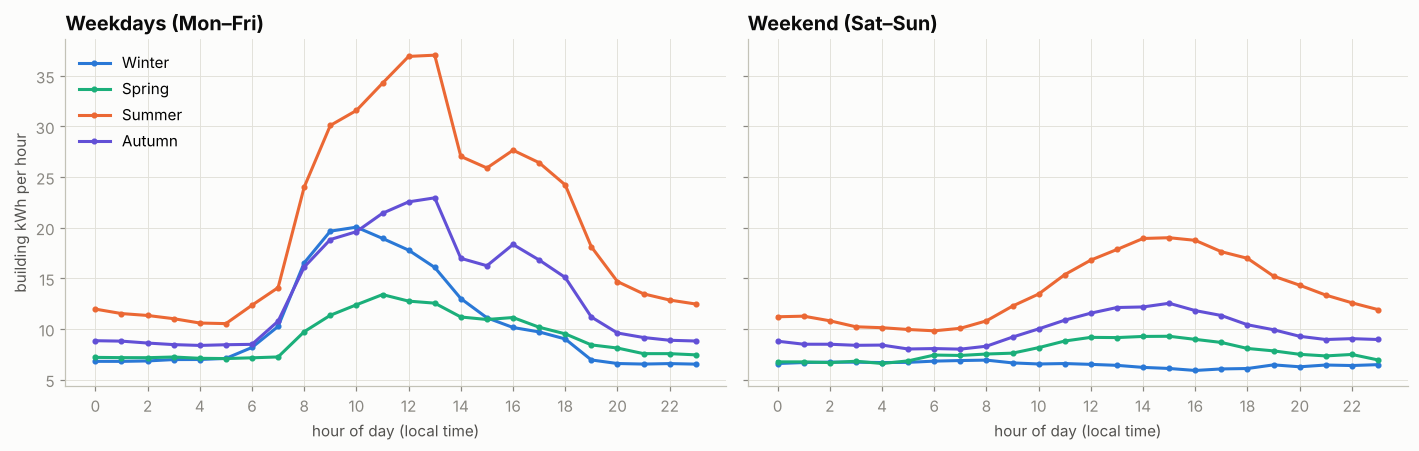

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for k, (title, mask) in enumerate([("Weekdays (Mon–Fri)", loc.dow < 5), ("Weekend (Sat–Sun)", loc.dow >= 5)]):
    sub = loc[mask]
    for s, col in [("Winter", C["blue"]), ("Spring", C["aqua"]), ("Summer", C["orange"]), ("Autumn", C["violet"])]:
        p = sub[sub.season == s].groupby("hour").total.mean()
        ax[k].plot(p.index, p.values, color=col, marker="o", ms=3, label=s)
    ax[k].set_title(title); ax[k].set_xticks(range(0, 24, 2)); ax[k].set_xlabel("hour of day (local time)")
ax[0].set_ylabel("building kWh per hour"); ax[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

night = loc[loc.hour < 6].total.mean()
work = loc[(loc.dow < 5) & (loc.hour.between(8, 19))].total.mean()
wkend = loc[(loc.dow >= 5) & (loc.hour.between(8, 19))].total.mean()
print(f"Night (00–06): {night:.1f} kWh/h | weekday 08–20: {work:.1f} kWh/h ({work/night:.1f}× night) | weekend 08–20: {wkend:.1f} kWh/h")
for s in ["Winter","Spring","Summer","Autumn"]:
    sub = loc[(loc.season == s) & (loc.dow < 5)]
    print(f"  {s:7s} weekday peak {sub.groupby('hour').total.mean().max():.1f} kWh/h at {sub.groupby('hour').total.mean().idxmax()}:00, night {sub[sub.hour<6].total.mean():.1f}")

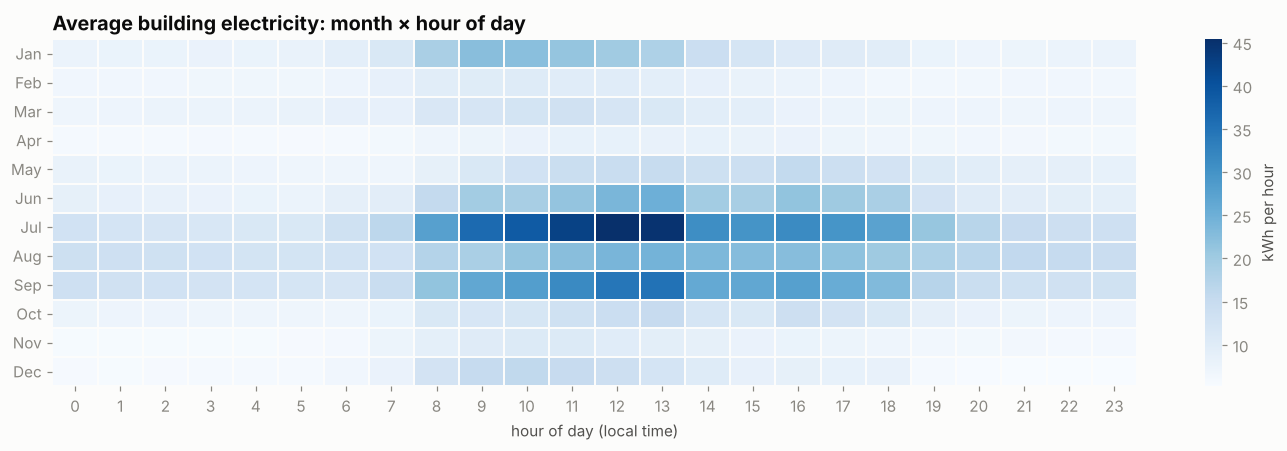

In [9]:
pivot = loc.groupby(["month", "hour"]).total.mean().unstack(); pivot.index = MONTHS
fig, ax = plt.subplots(figsize=(13, 4.2))
sns.heatmap(pivot, cmap="Blues", ax=ax, cbar_kws={"label": "kWh per hour"}, linewidths=0.3, linecolor=C["surf"]); ax.grid(False); ax.tick_params(axis="y", rotation=0)
ax.set_title("Average building electricity: month × hour of day"); ax.set_xlabel("hour of day (local time)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

> **Answer Q3: day vs. night, weekdays, seasons**
>
> * **Night (00–06):** a base load of about **8 kWh/h** (servers, fridges, standby, ventilation), slightly higher in summer (11 kWh/h).
> * **Weekday working hours (08–20):** about **18 kWh/h, 2.1× the night level**. The building switches on at 07–08 and winds down after 19–20, following the university timetable.
> * **Weekend:** almost flat, about **10 kWh/h**; only in summer is there a moderate midday bump from cooling.
> * **Seasons change the size and timing of the peak:** summer weekdays peak at **37 kWh/h around 13:00** (cooling at the hottest time of day); winter weekdays peak earlier, at **20 kWh/h around 10:00** (morning heating of cold rooms); spring is the mildest (13 kWh/h).
>
> Energy use is the product of **two drivers**: the **timetable** (when people are there) and the **weather** (how much heating or cooling is needed while they are there).

## 6. How fast does the system change? (Q4)

lag    1 h: electricity 0.93 | indoor T 1.00 | outdoor T 0.99
lag    3 h: electricity 0.73 | indoor T 1.00 | outdoor T 0.90
lag    6 h: electricity 0.43 | indoor T 0.99 | outdoor T 0.72
lag   12 h: electricity 0.14 | indoor T 0.99 | outdoor T 0.51
lag   24 h: electricity 0.73 | indoor T 0.99 | outdoor T 0.93
lag 1 week: electricity 0.73 | indoor T 0.97 | outdoor T 0.87
Hour-to-hour change of building electricity: median 0.7 kWh, 99th pct 17.9 kWh
Indoor temperature change follows outdoor temperature change with the strongest link at a lag of 2 h (r = 0.32)


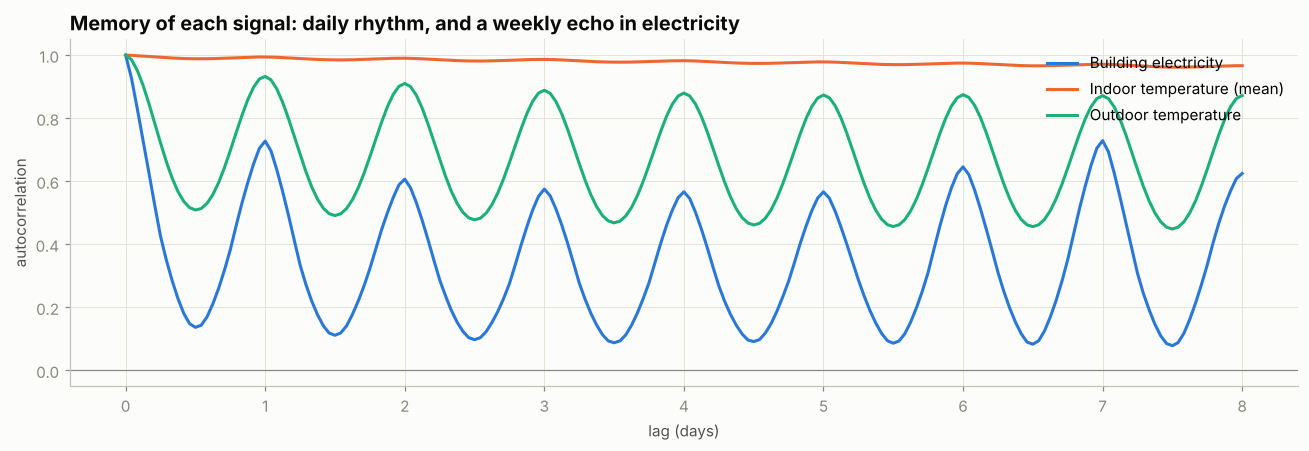

In [10]:
lags = np.arange(0, 24 * 8 + 1)
fig, ax = plt.subplots(figsize=(12, 4.2))
for col, name, color in [("total", "Building electricity", C["blue"]), ("tin", "Indoor temperature (mean)", C["orange"]), ("tmed", "Outdoor temperature", C["aqua"])]:
    s = df[col]; ax.plot(lags / 24, [s.autocorr(int(l)) for l in lags], color=color, label=name)
ax.axhline(0, color=C["muted"], lw=0.8); ax.set_xlabel("lag (days)"); ax.set_ylabel("autocorrelation")
ax.set_title("Memory of each signal: daily rhythm, and a weekly echo in electricity"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
for l, t in [(1, "1 h"), (3, "3 h"), (6, "6 h"), (12, "12 h"), (24, "24 h"), (168, "1 week")]:
    print(f"lag {t:>6}: electricity {df.total.autocorr(l):.2f} | indoor T {df.tin.autocorr(l):.2f} | outdoor T {df.tmed.autocorr(l):.2f}")
step = df.total.diff().abs()
print(f"Hour-to-hour change of building electricity: median {step.median():.1f} kWh, 99th pct {step.quantile(.99):.1f} kWh")

# Thermal lag: how many hours after outdoor temperature does indoor temperature follow?
xc = {k: df.tin.diff().corr(df.tmed.diff().shift(k)) for k in range(0, 13)}
best = max(xc, key=xc.get)
print(f"Indoor temperature change follows outdoor temperature change with the strongest link at a lag of {best} h (r = {xc[best]:.2f})")

> **Answer Q4: speed of change**
>
> | Process | Time scale | Evidence |
> |---|---|---|
> | Switching HVAC / building on and off | **within an hour** | energy changes by up to 18 kWh from one hour to the next (99th pct); HVAC changes and energy changes coincide in the same hour (Section 9) |
> | Memory of electricity use | **a few hours** | autocorrelation 0.93 after 1 h, 0.43 after 6 h, 0.14 after 12 h |
> | Indoor temperature | **hours to days** | follows outdoor temperature with a lag of about **2 h**; block-average swings only ~1 °C per day; autocorrelation stays > 0.97 for a week |
> | Daily and weekly routine | **24 h, 7 days** | autocorrelation of electricity back to 0.73 after exactly 1 day and 1 week |
> | Seasons and academic calendar | **months** | heating in winter, cooling in summer, closure in August |
>
> **Is the sampling fast enough?** For hourly or daily energy forecasts, yes: the meters report every 10 min, five to six times faster than the hourly changes we want to see. For single HVAC start-ups (minutes) it is not, and it does not need to be for this purpose.

## 7. How do the inputs affect the output? (Q5)

First the main physical driver: daily energy against daily outdoor temperature. A building that is heated and cooled shows a **V shape**: energy rises when it is colder than a heating balance temperature and when it is warmer than a cooling balance temperature. We fit this as a **degree-day model**, a standard model in building energy analysis.

Weekday degree-day model: R² = 0.70; heating below 14.5 °C (+28 kWh per °C·day), cooling above 18.0 °C (+39 kWh per °C·day), base load 178 kWh/day
Weekend days use 230 kWh/day on average vs 328 on weekdays


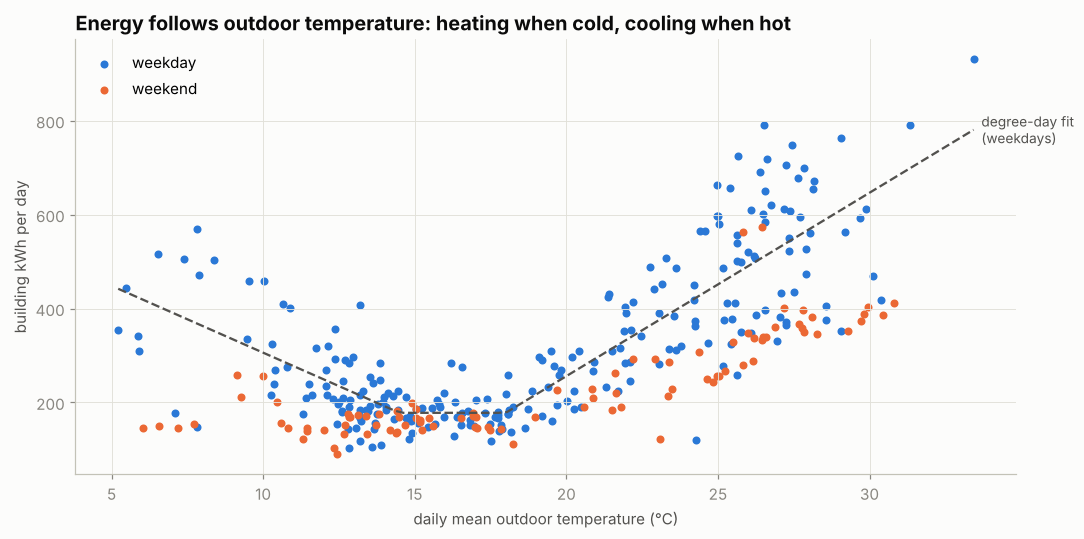

In [11]:
d = pd.DataFrame({"kWh": cons.total.resample("D").sum(min_count=20), "T": weather.tmed.resample("D").mean(),
                  "rad": weather.radmed.resample("D").mean()}).dropna()
d["weekday"] = d.index.dayofweek < 5
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(d[d.weekday]["T"], d[d.weekday].kWh, s=18, color=C["blue"], label="weekday")
ax.scatter(d[~d.weekday]["T"], d[~d.weekday].kWh, s=18, color=C["orange"], label="weekend")
ax.set_xlabel("daily mean outdoor temperature (°C)"); ax.set_ylabel("building kWh per day")
ax.set_title("Energy follows outdoor temperature: heating when cold, cooling when hot"); ax.legend(loc="upper left")

# Degree-day model on weekdays: energy = base + a·HDD + b·CDD  (search the best balance temperatures)
wk = d[d.weekday]; best = None
for th in np.arange(12, 20.5, 0.5):
    for tc in np.arange(th, 25.5, 0.5):
        X = np.c_[(th - wk["T"]).clip(lower=0), (wk["T"] - tc).clip(lower=0)]
        r2 = LinearRegression().fit(X, wk.kWh).score(X, wk.kWh)
        if best is None or r2 > best[0]: best = (r2, th, tc)
r2, th, tc = best
X = np.c_[(th - wk["T"]).clip(lower=0), (wk["T"] - tc).clip(lower=0)]; lr = LinearRegression().fit(X, wk.kWh)
tt = np.linspace(d["T"].min(), d["T"].max(), 100)
ax.plot(tt, lr.predict(np.c_[(th - tt).clip(min=0), (tt - tc).clip(min=0)]), color=C["ink2"], lw=1.5, ls="--")
ax.text(tt[-1], lr.predict([[0, tt[-1] - tc]])[0], "  degree-day fit\n  (weekdays)", color=C["ink2"], va="center", fontsize=9)
plt.tight_layout(); plt.show()
print(f"Weekday degree-day model: R² = {r2:.2f}; heating below {th:.1f} °C (+{lr.coef_[0]:.0f} kWh per °C·day), "
      f"cooling above {tc:.1f} °C (+{lr.coef_[1]:.0f} kWh per °C·day), base load {lr.intercept_:.0f} kWh/day")
print(f"Weekend days use {d[~d.weekday].kWh.mean():.0f} kWh/day on average vs {wk.kWh.mean():.0f} on weekdays")

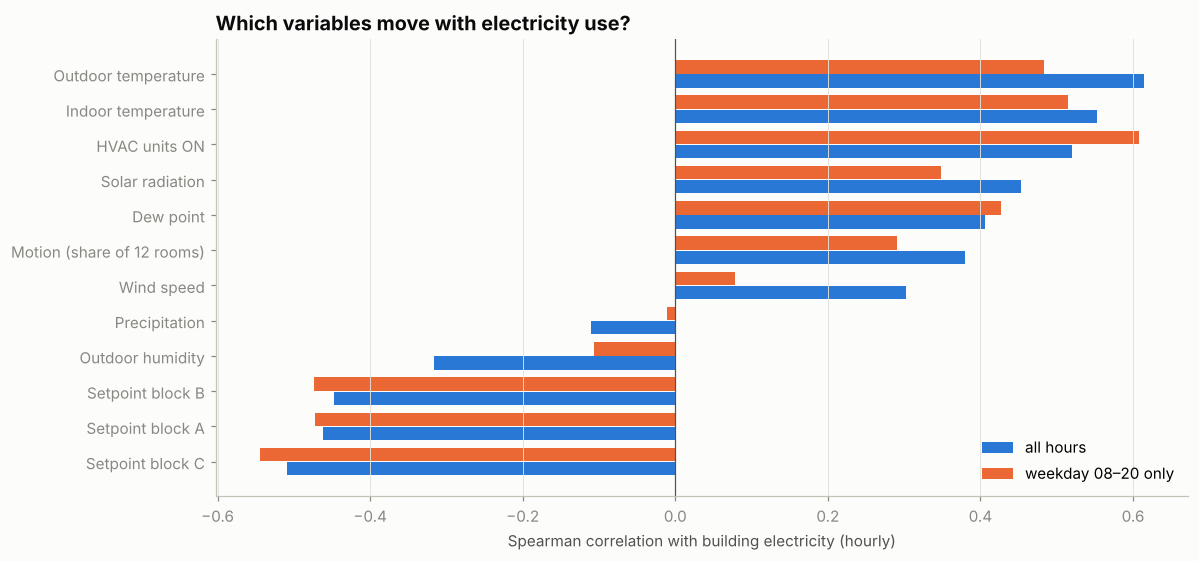

,all hours,weekday working hours
variable,,
Setpoint block C,-0.51,-0.54
Setpoint block A,-0.46,-0.47
Setpoint block B,-0.45,-0.47
Outdoor humidity,-0.32,-0.11
Precipitation,-0.11,-0.01
Wind speed,0.30,0.08
Motion (share of 12 rooms),0.38,0.29
Dew point,0.41,0.43
Solar radiation,0.45,0.35


In [12]:
cols = {"tmed": "Outdoor temperature", "radmed": "Solar radiation", "hrmed": "Outdoor humidity", "vvmed": "Wind speed",
        "dewpt": "Dew point", "prec": "Precipitation", "on": "HVAC units ON", "tin": "Indoor temperature",
        "occ": "Motion (share of 12 rooms)", "sp_A": "Setpoint block A", "sp_B": "Setpoint block B", "sp_C": "Setpoint block C"}
work = loc[(loc.dow < 5) & loc.hour.between(8, 19)]          # working hours only, so the daily on/off cycle does not dominate
rows = []
for c, name in cols.items():
    rows.append((name, df[c].corr(df.total, method="spearman"), work[c].corr(work.total, method="spearman")))
cr = pd.DataFrame(rows, columns=["variable", "all hours", "weekday working hours"]).set_index("variable").sort_values("all hours")
fig, ax = plt.subplots(figsize=(11, 5.2))
y = np.arange(len(cr))
ax.barh(y - 0.2, cr["all hours"], height=0.38, color=C["blue"], label="all hours")
ax.barh(y + 0.2, cr["weekday working hours"], height=0.38, color=C["orange"], label="weekday 08–20 only")
ax.set_yticks(y); ax.set_yticklabels(cr.index); ax.axvline(0, color=C["ink2"], lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("Spearman correlation with building electricity (hourly)"); ax.legend(loc="lower right")
ax.set_title("Which variables move with electricity use?")
plt.tight_layout(); plt.show()
cr.round(2)

> **Answer Q5: how do the inputs affect the output?**
>
> * **Outdoor temperature is the dominant driver.** On weekdays, a simple degree-day model explains **70 % of the day-to-day variation** in building energy: about **+39 kWh per degree-day above 18 °C** (cooling) and **+28 kWh per degree-day below 14.5 °C** (heating), on top of a base load of ~180 kWh/day.
> * **Weekend vs. weekday** shifts the whole curve: weekends use ~230 kWh/day vs. ~330 on weekdays, even at the same temperature. The few low "weekday" points at low temperatures are holidays (Christmas, early January).
> * At the hourly level, the strongest relations are **outdoor temperature (ρ = 0.61)**, **indoor temperature (0.55)**, **HVAC units ON (0.52; 0.61 in working hours)** and **solar radiation (0.45)**. **Motion** in the 12 monitored rooms also moves with energy (0.38).
> * **Setpoints correlate negatively** (−0.45 to −0.51): in summer, cooling setpoints are lower, and lower cooling setpoints mean more cooling work. Part of this is a seasonal co-movement, so the setpoint effect must be modelled together with weather, not read from a single correlation.
>
> Compared with a household dataset, the inputs here have **clear physical meaning and much stronger links** to the output.

## 8. How many variables do we really need? (Q6)

Daily electricity correlation between blocks:
      A     B     C
A  1.00 -0.07  0.71
B -0.07  1.00  0.10
C  0.71  0.10  1.00


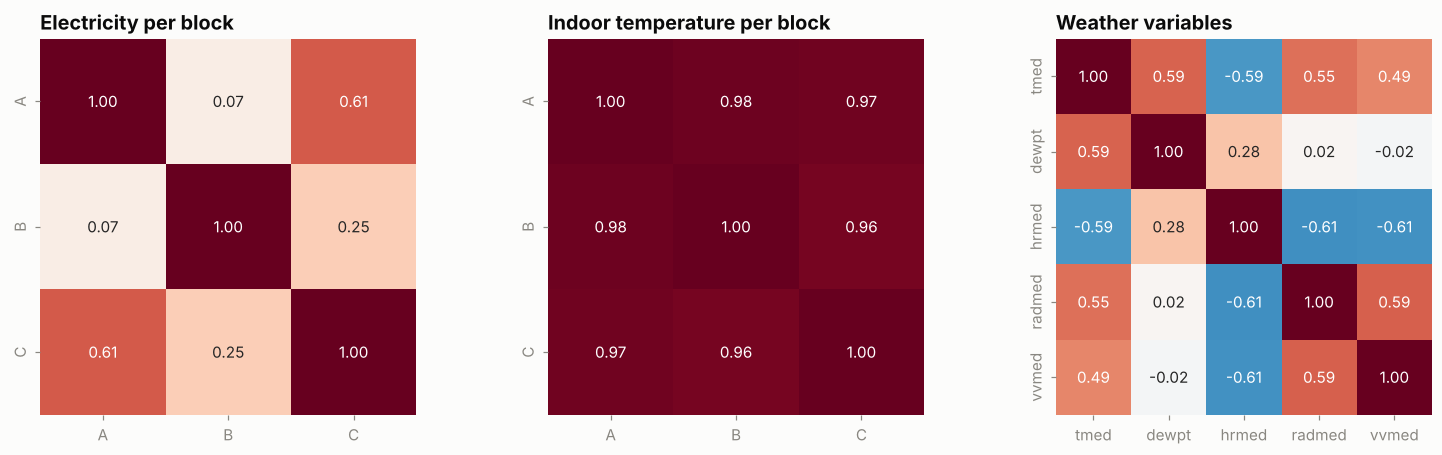

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
pairs = [("Electricity per block", cons[["A","B","C"]]), ("Indoor temperature per block", tin), ("Weather variables", weather[["tmed","dewpt","hrmed","radmed","vvmed"]])]
for a, (title, t) in zip(ax, pairs):
    sns.heatmap(t.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=a, cbar=False, square=True)
    a.set_title(title); a.grid(False)
plt.tight_layout(); plt.show()
dly = cons[["A","B","C"]].resample("D").sum(min_count=20)
print("Daily electricity correlation between blocks:"); print(dly.corr().round(2).to_string())

> **Answer Q6: how many variables?**
>
> * **Indoor temperatures of the three blocks are nearly identical** (r ≈ 0.96–0.98): one indoor temperature signal is enough at block level.
> * **Electricity of the three blocks is not interchangeable** (B is uncorrelated with A; A and C r ≈ 0.6–0.7): keep **one target per block**.
> * **Weather:** temperature, radiation, humidity and wind are moderately correlated (|r| ≈ 0.5–0.6) because they all follow the daily sun cycle. Outdoor temperature + solar radiation carry most of the useful information; humidity and dew point add little; precipitation is almost always zero in Murcia.
>
> A sensible first input set: **hour, weekday, holiday/academic calendar, outdoor temperature, solar radiation, last week's load at the same hour**, and later **HVAC units ON / setpoint per block** once that series is cleaned.

## 9. Cause or effect? (Q7)

Two checks. (1) When the number of HVAC units ON changes, does electricity change at the same time, before or after? (2) The feedback trap from Session 2: do units switch ON *because* rooms are warm, which would make HVAC partly an effect of temperature?

Block A: corr(Δ energy, Δ units ON) same hour = 0.45, HVAC 1 h earlier = 0.12, HVAC 1 h later = 0.12
Block B: corr(Δ energy, Δ units ON) same hour = 0.59, HVAC 1 h earlier = 0.03, HVAC 1 h later = 0.08
Block C: corr(Δ energy, Δ units ON) same hour = 0.45, HVAC 1 h earlier = 0.18, HVAC 1 h later = 0.17
Summer: outdoor T vs units ON r = -0.12


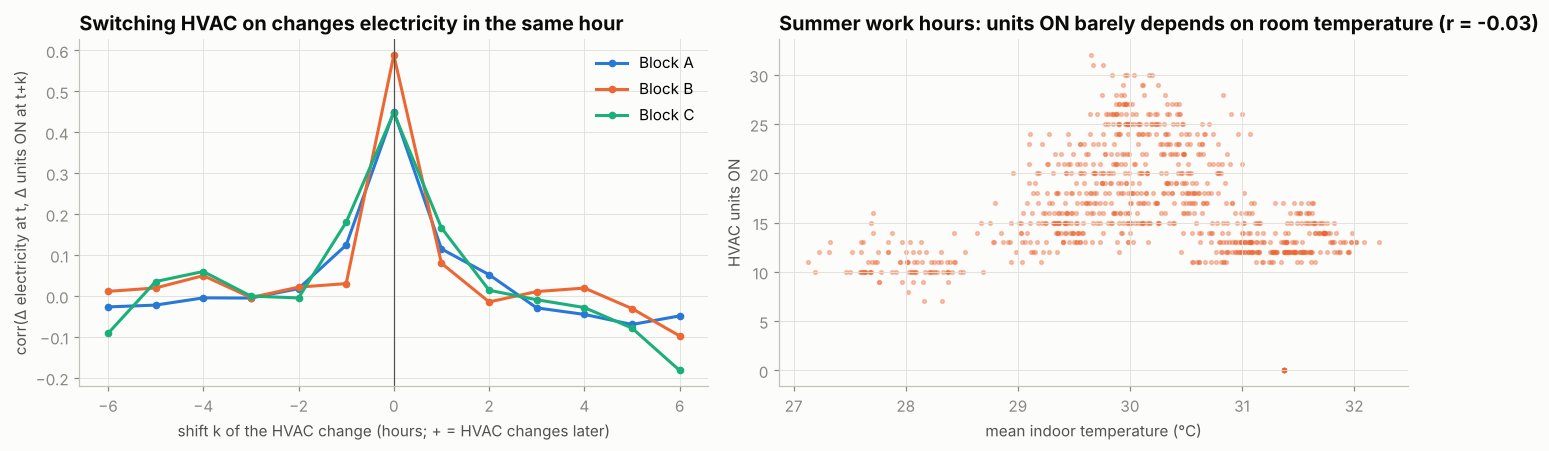

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ks = np.arange(-6, 7)
for b in "ABC":
    e, u = cons[b].diff(), units_on[b].reindex(cons.index).diff()
    ax[0].plot(ks, [e.corr(u.shift(-k)) for k in ks], color=BLOCK_COL[b], marker="o", ms=4, label=f"Block {b}")
ax[0].axvline(0, color=C["ink2"], lw=0.8); ax[0].set_xlabel("shift k of the HVAC change (hours; + = HVAC changes later)")
ax[0].set_ylabel("corr(Δ electricity at t, Δ units ON at t+k)"); ax[0].set_title("Switching HVAC on changes electricity in the same hour")
ax[0].legend(loc="upper right")

# Feedback check: do more units switch ON when the rooms are warmer?
m = df.dropna(subset=["tmed","on","tin"])
summer = m.tz_convert(TZ); summer = summer[(summer.index.month.isin([6,7,8,9])) & (summer.index.dayofweek < 5) & summer.index.hour.isin(range(9,19))]
ax[1].scatter(summer.tin, summer.on, s=6, alpha=0.35, color=C["orange"])
ax[1].set_xlabel("mean indoor temperature (°C)"); ax[1].set_ylabel("HVAC units ON")
ax[1].set_title(f"Summer work hours: units ON barely depends on room temperature (r = {summer.tin.corr(summer.on):.2f})")
plt.tight_layout(); plt.show()
for b in "ABC":
    e, u = cons[b].diff(), units_on[b].reindex(cons.index).diff()
    print(f"Block {b}: corr(Δ energy, Δ units ON) same hour = {e.corr(u):.2f}, HVAC 1 h earlier = {e.corr(u.shift(1)):.2f}, HVAC 1 h later = {e.corr(u.shift(-1)):.2f}")
print(f"Summer: outdoor T vs units ON r = {summer.tmed.corr(summer.on):.2f}")

> **Answer Q7: cause or effect?**
>
> * **HVAC → electricity is a direct causal link.** Changes in the number of units ON and changes in block electricity happen in the **same hour** (r = 0.45–0.59); one hour before or after, the link almost disappears (≈ 0.1). With hourly data we cannot resolve it more finely, and we do not need to: the arrow is physical (a running compressor draws power).
> * **Outdoor temperature → indoor temperature** follows with about **2 hours** of delay (Section 6), the thermal inertia of the building.
> * **No strong thermostat feedback in the data.** In summer working hours, the number of units ON is almost unrelated to room temperature (r ≈ −0.03) and to outdoor temperature (r ≈ −0.12). People switch units on **when they arrive**, by schedule and habit, not when a sensor crosses a threshold. This is good news for modelling: HVAC on/off behaves like an **input** set by people, not like a reaction of the system.
> * **Caution:** "units ON" and "occupancy" are linked (units run when rooms are used), so their effects must not be double counted.

## 10. What can we control, and what can we not? (Q8)

Setpoint range per block (°C): {'A': (np.float64(14.1), np.float64(21.2)), 'B': (np.float64(22.2), np.float64(25.3)), 'C': (np.float64(23.4), np.float64(25.5))}


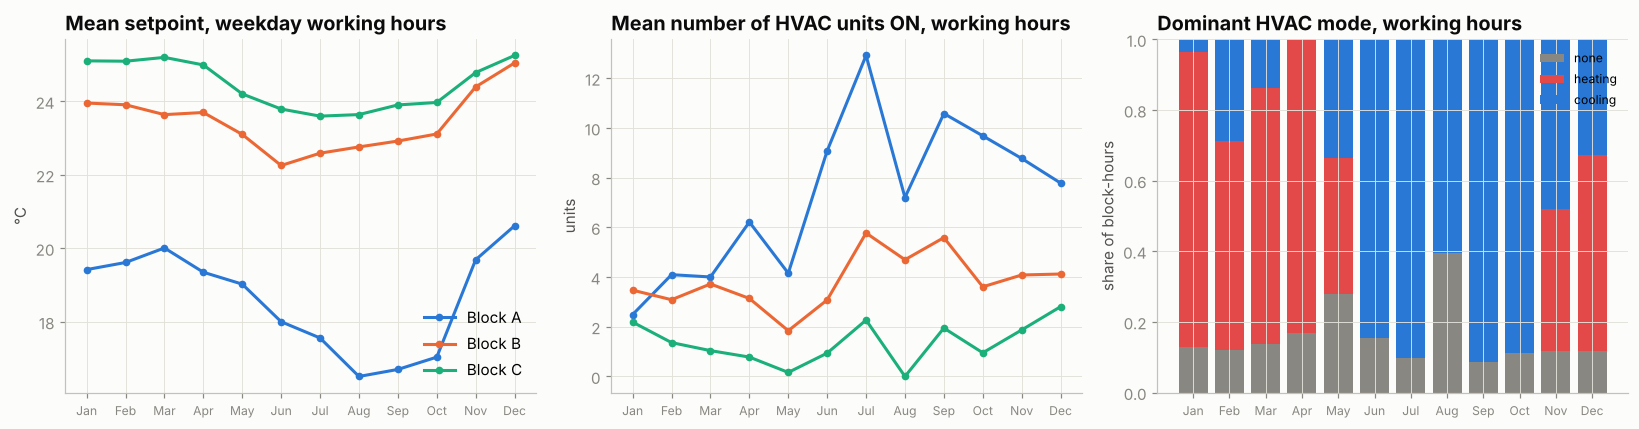

In [15]:
sp_m = setpoint.copy(); sp_m.index = sp_m.index.tz_convert(TZ)
on_m = units_on.copy(); on_m.index = on_m.index.tz_convert(TZ)
md = mode.copy(); md.index = md.index.tz_convert(TZ)
work_mask = lambda x: (x.index.dayofweek < 5) & (x.index.hour >= 8) & (x.index.hour < 20)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for b in "ABC":
    s = sp_m[work_mask(sp_m)][b].groupby(sp_m[work_mask(sp_m)].index.month).mean()
    ax[0].plot(MONTHS[:len(s)], s.values, color=BLOCK_COL[b], marker="o", ms=4, label=f"Block {b}")
    o = on_m[work_mask(on_m)][b].groupby(on_m[work_mask(on_m)].index.month).mean()
    ax[1].plot(MONTHS[:len(o)], o.values, color=BLOCK_COL[b], marker="o", ms=4, label=f"Block {b}")
ax[0].set_title("Mean setpoint, weekday working hours"); ax[0].set_ylabel("°C"); ax[0].legend(loc="lower right")
ax[1].set_title("Mean number of HVAC units ON, working hours"); ax[1].set_ylabel("units")
mm = md[work_mask(md)].stack().groupby([md[work_mask(md)].stack().index.get_level_values(0).month, md[work_mask(md)].stack().values]).size().unstack(fill_value=0)
mm = mm.div(mm.sum(axis=1), axis=0)
bottom = np.zeros(len(mm))
for k, (lab, col) in enumerate([("none", C["muted"]), ("heating", C["red"]), ("cooling", C["blue"])]):
    if k in mm.columns:
        ax[2].bar([MONTHS[i-1] for i in mm.index], mm[k], bottom=bottom, color=col, label=lab, width=0.8); bottom += mm[k].values
ax[2].set_title("Dominant HVAC mode, working hours"); ax[2].set_ylabel("share of block-hours"); ax[2].legend(loc="upper right", fontsize=8)
for a in ax: a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print("Setpoint range per block (°C):", {b: (round(setpoint[b].min(),1), round(setpoint[b].max(),1)) for b in "ABC"})

In [16]:
pd.DataFrame([
    ("HVAC on/off (87 units)",            "u  controllable",            "yes (per unit, aggregated per block)", "Direct lever on electricity"),
    ("HVAC setpoint (°C)",                "u  controllable",            "yes",                                   "Lever on comfort and energy"),
    ("HVAC mode (heat / cool)",           "u  controllable",            "yes",                                   "Follows the season"),
    ("Outdoor temperature, radiation, humidity, wind", "d  not controllable", "yes (local station, 10 min)",       "Main driver of HVAC demand"),
    ("Occupancy / plug loads",            "d  not controllable by the twin", "partly (motion + CO2 in 12 rooms)", "Drives the working-hours load"),
    ("Room temperatures",                 "x  states",                  "yes (~90 sensors)",                     "Result of weather + HVAC"),
    ("Heat stored in walls / slabs",      "x  hidden state",            "no",                                    "Explains the slow indoor response"),
    ("Electricity per block",             "y  output (target)",         "yes (3 meters)",                        "What we forecast"),
], columns=["factor", "role", "in the data?", "comment"]).set_index("factor")

,role,in the data?,comment
factor,,,
HVAC on/off (87 units),u controllable,"yes (per unit, aggregated per block)",Direct lever on electricity
HVAC setpoint (°C),u controllable,yes,Lever on comfort and energy
HVAC mode (heat / cool),u controllable,yes,Follows the season
"Outdoor temperature, radiation, humidity, wind",d not controllable,"yes (local station, 10 min)",Main driver of HVAC demand
Occupancy / plug loads,d not controllable by the twin,partly (motion + CO2 in 12 rooms),Drives the working-hours load
Room temperatures,x states,yes (~90 sensors),Result of weather + HVAC
Heat stored in walls / slabs,x hidden state,no,Explains the slow indoor response
Electricity per block,y output (target),yes (3 meters),What we forecast


> **Answer Q8: controllable vs. not controllable**
>
> * **Controllable (inputs u), recorded in the data:** HVAC **on/off**, **setpoint** and **mode** of each of the 87 units. The data shows them being used: setpoints are lowered in summer (block A from ~20 °C in spring to ~16.5 °C in August), modes switch from **heating (Jan–Apr, Nov–Dec)** to **cooling (May–Oct)**, and the number of units ON roughly triples in July.
> * **Not controllable (disturbances d):** outdoor temperature, solar radiation, humidity and wind; **occupancy** and **plug loads** (computers, labs, lighting) as far as the twin is concerned; the **academic calendar**.
> * **States (x):** room temperatures, a result of weather and HVAC. The **heat stored in walls and slabs** is hidden.
>
> **Consequence for the project:** because the levers are recorded, a model of this building can answer **what-if questions** ("what if block A's summer setpoint were 2 °C higher?"). That is the step from a *digital model* towards a *digital twin*: once a live feed arrives (*shadow*) and setpoints are sent back to the units, the loop is closed (*twin*).

## 11. What is missing, and why would it help? (Q9)

To see how far the measured inputs get us, we compare simple predictors on an **honest chronological split**: train on **8 Jan – 31 Oct**, test on **1 Nov – 17 Dec**, which the models have never seen. (The test ends on 17 Dec because the HVAC and weather data stop there.) The error is the **mean absolute error (MAE)** in kWh per hour for the whole building.

Train: 08 Jan – 31 Oct (6,774 h)   Test: 01 Nov – 17 Dec (1,031 h)
Mean electricity: train 13.2 kWh/h, test 8.1 kWh/h


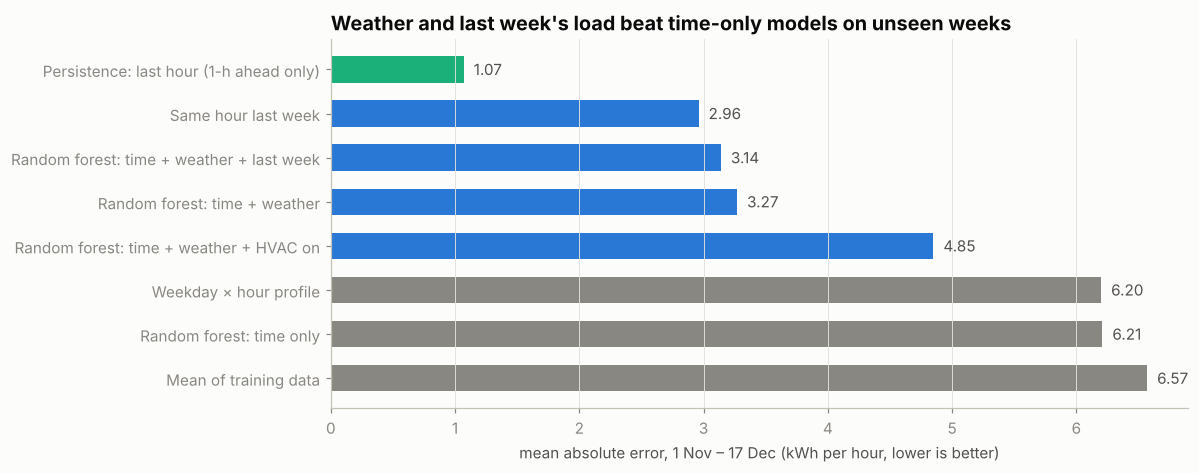

,MAE (kWh/h),R²
Mean of training data,6.57,-1.09
Weekday × hour profile,6.20,-1.26
Same hour last week,2.96,-0.13
Random forest: time only,6.21,-1.27
Random forest: time + weather,3.27,-0.01
Random forest: time + weather + HVAC on,4.85,-1.21
Random forest: time + weather + last week,3.14,0.10
Persistence: last hour (1-h ahead only),1.07,0.79


In [17]:
m = loc.copy()
m["lag1"], m["lag24"], m["lag168"] = m.total.shift(1), m.total.shift(24), m.total.shift(168)
m = m.dropna(subset=["total", "tmed", "radmed", "hrmed", "on", "lag168", "lag1", "lag24"])
tr, te = m[m.index < "2021-11-01"], m[(m.index >= "2021-11-01") & (m.index < "2021-12-18")]
y = te.total
def rf(): return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0)
TIME, WEATHER = ["hour", "dow"], ["tmed", "radmed", "hrmed"]
R = {}
R["Mean of training data"] = np.full(len(te), tr.total.mean())
prof = tr.groupby(["dow", "hour"]).total.mean(); R["Weekday × hour profile"] = np.array([prof[(a, b)] for a, b in zip(te.dow, te.hour)])
R["Same hour last week"] = te.lag168.values
R["Random forest: time only"] = rf().fit(tr[TIME], tr.total).predict(te[TIME])
R["Random forest: time + weather"] = rf().fit(tr[TIME + WEATHER], tr.total).predict(te[TIME + WEATHER])
R["Random forest: time + weather + HVAC on"] = rf().fit(tr[TIME + WEATHER + ["on"]], tr.total).predict(te[TIME + WEATHER + ["on"]])
R["Random forest: time + weather + last week"] = rf().fit(tr[TIME + WEATHER + ["lag168"]], tr.total).predict(te[TIME + WEATHER + ["lag168"]])
R["Persistence: last hour (1-h ahead only)"] = te.lag1.values
res = pd.DataFrame({k: {"MAE (kWh/h)": mean_absolute_error(y, p), "R²": r2_score(y, p)} for k, p in R.items()}).T.round(2)

fig, ax = plt.subplots(figsize=(11, 4.4))
o = res["MAE (kWh/h)"].sort_values(ascending=False)
cols_ = [C["muted"] if ("Mean" in k or "profile" in k or "time only" in k) else (C["aqua"] if "Persistence" in k else C["blue"]) for k in o.index]
ax.barh(o.index, o.values, color=cols_, height=0.6)
for i, v in enumerate(o.values): ax.text(v + 0.08, i, f"{v:.2f}", va="center", color=C["ink2"])
ax.set_xlabel("mean absolute error, 1 Nov – 17 Dec (kWh per hour, lower is better)"); ax.grid(axis="y", visible=False)
ax.set_title("Weather and last week's load beat time-only models on unseen weeks")
plt.tight_layout(); plt.show()
print(f"Train: {tr.index.min():%d %b} – {tr.index.max():%d %b} ({len(tr):,} h)   Test: {te.index.min():%d %b} – {te.index.max():%d %b} ({len(te):,} h)")
print(f"Mean electricity: train {tr.total.mean():.1f} kWh/h, test {y.mean():.1f} kWh/h")
res

**What the comparison shows**

* **Time-only models fail on unseen weeks** (MAE ≈ 6.2 kWh/h, no better than the training mean). The training period contains the hot summer, so "average 11:00 on a Tuesday" is far too high for November.
* **Adding weather halves the error** (MAE 3.27). The physics carries over to a new season.
* **Last week's load at the same hour** is a strong signal (MAE 2.96 alone, 3.14 combined with weather). It captures the current state of the building: term vs. holiday, which rooms are in use.
* **Adding "HVAC units ON" makes it worse** (MAE 4.85). In Nov–Dec more units are logged ON than in January while energy is lower, which fits the log quality problem from Section 3. Clean this series before using it.
* **Persistence** (MAE 1.07) is only possible one hour ahead and is not a day-ahead forecast; it shows how much the last hour already tells.

> **Answer Q9: what is missing, and why it matters**
>
> | Missing information | Why it would make the output more reliable |
> |---|---|
> | **Academic calendar / holidays** (lecture periods, exams, August closure, Christmas) | Explains the August dip and the low "weekday" holidays that weather cannot explain. Easy to add from the university calendar. |
> | **Occupancy in all rooms** (now motion + CO₂ in only 12 of ~90 rooms) | Occupancy decides when units are switched on and drives plug loads. The 12-room sample is a useful proxy but not representative of all three blocks. |
> | **HVAC electricity per unit or per block** (sub-metering) | The block meters mix HVAC with lights, computers and labs. Separating HVAC power would allow a clean physical HVAC model. |
> | **A clean, complete HVAC log** | The levers are recorded, but with suspicious constant stretches and an early end (18 Dec). |
> | **Heat stored in the building (thermal mass)** | A hidden state behind the 2-hour indoor delay; it can be estimated with a simple RC (resistance–capacitance) thermal model. |
> | **A second year** | Needed to test a model on the *same season* it has never seen (Section 12). |
>
> **Why don't we have them?** The dataset was built from the building's existing management system (meters, HVAC controllers, room sensors). Occupancy sensors were only installed in a pilot set of rooms; sub-metering of HVAC was not part of the installation; the academic calendar is simply not a sensor signal.

## 12. Is the history long enough? (Q10)

Share of test hours with outdoor temperature outside the training range: 0.0%
Share of test hours with solar radiation outside the training range: 0.0%
Share of test hours with HVAC units ON outside the training range: 0.0%


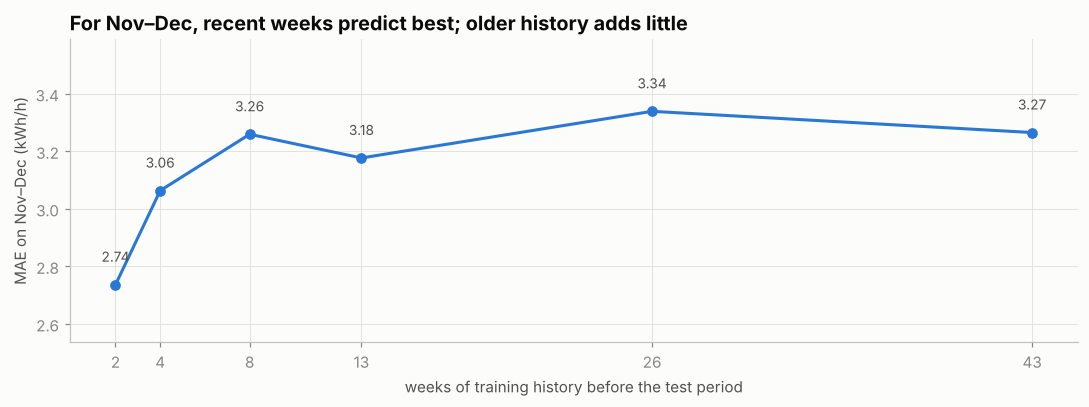

,weeks of history,hours,MAE (kWh/h),test hours outside training temperature range
0,2,335,2.736,0.361
1,4,531,3.064,0.361
2,8,1203,3.259,0.361
3,13,1831,3.177,0.361
4,26,4015,3.339,0.343
5,43,6774,3.265,0.000


In [18]:
# 1) Coverage: are the test conditions inside what the model saw in training?
for c, n in [("tmed", "outdoor temperature"), ("radmed", "solar radiation"), ("on", "HVAC units ON")]:
    print(f"Share of test hours with {n} outside the training range: {((te[c] > tr[c].max()) | (te[c] < tr[c].min())).mean():.1%}")

# 2) How much history does a weather model need? Train on the last N weeks before 1 Nov only.
feats = TIME + WEATHER
rows = []
for wks in [2, 4, 8, 13, 26, 43]:
    sub = tr[tr.index > tr.index.max() - pd.Timedelta(weeks=wks)]
    p = rf().fit(sub[feats], sub.total).predict(te[feats])
    tmin, tmax = sub.tmed.min(), sub.tmed.max()
    rows.append((wks, len(sub), mean_absolute_error(y, p), ((te.tmed < tmin) | (te.tmed > tmax)).mean()))
hist = pd.DataFrame(rows, columns=["weeks of history", "hours", "MAE (kWh/h)", "test hours outside training temperature range"])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hist["weeks of history"], hist["MAE (kWh/h)"], color=C["blue"], marker="o")
for _, r in hist.iterrows(): ax.text(r["weeks of history"], r["MAE (kWh/h)"] + 0.08, f"{r['MAE (kWh/h)']:.2f}", ha="center", color=C["ink2"], fontsize=9)
ax.set_xlabel("weeks of training history before the test period"); ax.set_ylabel("MAE on Nov–Dec (kWh/h)")
ax.set_title("For Nov–Dec, recent weeks predict best; older history adds little"); ax.set_xticks(hist["weeks of history"]); ax.set_ylim(hist["MAE (kWh/h)"].min() - 0.2, hist["MAE (kWh/h)"].max() + 0.25)
plt.tight_layout(); plt.show()
hist.round(3)

In [19]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(m[feats], m.total, test_size=0.2, random_state=0)
r2_rand = r2_score(yte, rf().fit(Xtr, ytr).predict(Xte))
print(f"Same weather model, RANDOM 80/20 split: R² = {r2_rand:.2f}  vs  chronological (Nov–Dec) R² = {res.loc['Random forest: time + weather', 'R²']:.2f}")
print(f"Test-period variance is small (std {y.std():.1f} kWh/h vs {m.total.std():.1f} over the year), so R² is harsh on Nov–Dec: compare models by MAE.")

Same weather model, RANDOM 80/20 split: R² = 0.69  vs  chronological (Nov–Dec) R² = -0.01
Test-period variance is small (std 4.9 kWh/h vs 9.7 over the year), so R² is harsh on Nov–Dec: compare models by MAE.


> **Answer Q10: is the history long enough?**
>
> **Yes for a first forecasting model, with one limitation.**
> * **One full year covers every season once:** winter heating, spring, summer cooling, autumn. With all training data before November, **0 % of the test hours** have outdoor conditions outside what the model has seen. Training on only the last 26 weeks before November would leave **34–36 % of the test hours colder** than anything in training.
> * **Recent weeks matter most for the level:** for Nov–Dec, a weather model trained on just the **last 2 weeks** has the lowest error (MAE 2.74); adding older weeks raises it slightly (3.1–3.3). The building's use (term, occupancy) drifts, so the model should be **retrained regularly on recent data**, which is exactly the twin's *update loop*.
> * **The limitation:** with one year, every season appears only once. We can test on *later* weeks, but not on the *same season of a new year* (e.g. train on summer 2021, test on summer 2022). Two years would be ideal.
> * **Use chronological splits only.** The same weather model scores **R² = 0.69 on a random split** but about 0 on the honest Nov–Dec split: random splits leak information between neighbouring hours. Because Nov–Dec varies little, R² is harsh there; compare models by **MAE**.

## 13. Summary of answers

| # | Question | Short answer |
|---|---|---|
| Q1 | Physical system? | **Yes.** University building, 3 blocks, 87 HVAC units, ~90 room sensors, local weather station. A physical chain links weather → HVAC → electricity. |
| Q2 | Data quality? | Usable but needs cleaning: two meter outages (Aug, Dec) with lumped readings, weather gaps (Oct, from 18 Dec), HVAC log ends 18 Dec and has long constant stretches. 1.8 % of electricity hours missing. |
| Q3 | Day/night, weekday, seasons? | Night ~8 kWh/h; weekday 08–20 ~18 kWh/h (2.1×); weekends flat ~10. Summer peak 37 kWh/h at 13:00, winter peak 20 kWh/h at 10:00. July highest month, August dip (closure). |
| Q4 | Speed of change? | Energy: within the hour (switching), memory of a few hours; indoor temperature follows outdoor with ~2 h delay; strong 24 h and 7-day cycles; seasons. |
| Q5 | Inputs → output? | Outdoor temperature dominates: a degree-day model explains 70 % of weekday daily energy. HVAC ON, solar radiation, motion also matter. |
| Q6 | How many variables? | Few: time, weekday, calendar, outdoor temperature, radiation, last week's load; one target per block; one indoor temperature is enough. |
| Q7 | Cause or effect? | HVAC → electricity is direct (same hour). Outdoor → indoor temperature with ~2 h lag. No strong thermostat feedback: units are switched by schedule. |
| Q8 | Controllable? | **Yes:** HVAC on/off, setpoint, mode are recorded levers. Weather, occupancy, calendar are disturbances. Enables what-if analysis towards a twin. |
| Q9 | Missing / hidden? | Academic calendar, occupancy beyond 12 rooms, HVAC sub-metering, a clean HVAC log, thermal mass (hidden state), a second year. |
| Q10 | Enough history? | One full year covers all seasons (0 % of test conditions unseen). Recent weeks matter most → regular retraining. Only one year, so a same-season test is impossible. |

### What this means for the modelling stage

1. **Target:** hourly electricity **per block** (A, B and C behave differently), with day-ahead forecasts as the main purpose.
2. **Inputs:** hour, weekday, a **holiday/academic-calendar flag** (to add), outdoor temperature, solar radiation, last week's load; HVAC units ON and setpoint once the log is cleaned. Use only values known at forecast time.
3. **Fair test:** chronological split (train to 31 Oct, test 1 Nov – 17 Dec), plus a rolling re-training check for the update loop.
4. **Baselines to beat:** *same hour last week* (MAE 2.96 kWh/h) and the *weekday × hour profile* (MAE 6.20).
5. **Physics-based option:** a degree-day or simple RC thermal model as the interpretable, physics-justified model, compared with a data-driven model (e.g. random forest).
6. **Twin perspective:** setpoint and on/off are the levers for what-if scenarios (e.g. raising summer setpoints); a live meter feed would make it a shadow, and sending setpoints back would close the loop.